# Task 1 - Data Exploration
식약처 조리식품 레시피 DB (COOKRCP01). 데이터 받는 방법은 README 참고해주세요.

In [2]:
import json, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'  # 맥은 AppleGothic
plt.rcParams['axes.unicode_minus'] = False

## 데이터 불러오기

In [3]:
rows = []
for f in ['data/recipes_1_1000.json', 'data/recipes_1001_2000.json']:
    with open(f, encoding='utf-8') as fp:
        rows += json.load(fp)['COOKRCP01']['row']

df = pd.DataFrame(rows)
df = df.replace('', np.nan)
df.shape

(1156, 55)

In [4]:
nut = ['INFO_ENG', 'INFO_CAR', 'INFO_PRO', 'INFO_FAT', 'INFO_NA']
for c in nut:
    df[c] = pd.to_numeric(df[c])
df['RCP_SEQ'] = pd.to_numeric(df['RCP_SEQ'])

steps = [c for c in df.columns if re.fullmatch(r'MANUAL\d\d', c)]
df['n_steps'] = df[steps].notna().sum(axis=1)

cols = ['RCP_SEQ', 'RCP_NM', 'RCP_PAT2', 'RCP_WAY2', 'RCP_PARTS_DTLS', 'INFO_WGT'] + nut + ['HASH_TAG', 'RCP_NA_TIP', 'n_steps']
df[cols].dtypes

RCP_SEQ             int64
RCP_NM                str
RCP_PAT2              str
RCP_WAY2              str
RCP_PARTS_DTLS        str
INFO_WGT              str
INFO_ENG          float64
INFO_CAR          float64
INFO_PRO          float64
INFO_FAT          float64
INFO_NA           float64
HASH_TAG              str
RCP_NA_TIP            str
n_steps             int64
dtype: object

In [5]:
df[['RCP_SEQ', 'RCP_NM', 'RCP_PAT2', 'RCP_WAY2', 'INFO_ENG', 'INFO_NA', 'n_steps']].head()

,RCP_SEQ,RCP_NM,RCP_PAT2,RCP_WAY2,INFO_ENG,INFO_NA,n_steps
0,28,새우 두부 계란찜,반찬,찌기,220.0,99.0,3
1,29,부추 콩가루 찜,반찬,찌기,215.0,240.0,3
2,31,방울토마토 소박이,반찬,기타,45.0,277.0,3
3,32,순두부 사과 소스 오이무침,반찬,기타,75.0,22.0,3
4,33,사과 새우 북엇국,국&찌개,끓이기,65.0,78.0,3


In [6]:
print(df.loc[0, 'RCP_PARTS_DTLS'])

새우두부계란찜
연두부 75g(3/4모), 칵테일새우 20g(5마리), 달걀 30g(1/2개), 생크림 13g(1큰술), 설탕 5g(1작은술), 무염버터 5g(1작은술)
고명
시금치 10g(3줄기)


## 결측치, 중복

In [7]:
na = df[cols].isna().sum()
pd.DataFrame({'missing': na, 'rate(%)': (na / len(df) * 100).round(1)})[na > 0]

,missing,rate(%)
RCP_PARTS_DTLS,3,0.3
INFO_WGT,871,75.3
HASH_TAG,799,69.1
RCP_NA_TIP,54,4.7


In [8]:
print('재료 정보 없음:', (df.RCP_PARTS_DTLS.isna() | (df.RCP_PARTS_DTLS.str.len() < 3)).sum())
print('RCP_SEQ 중복:', df.RCP_SEQ.duplicated().sum())

same_name = df.RCP_NM.duplicated(keep=False)
exact_dup = df.duplicated(subset=['RCP_NM', 'RCP_PARTS_DTLS'])
print('메뉴명 중복:', same_name.sum(), '/ 완전 중복:', exact_dup.sum())
df[same_name].sort_values('RCP_NM')[['RCP_SEQ', 'RCP_NM', 'INFO_ENG']]

재료 정보 없음: 4
RCP_SEQ 중복: 0
메뉴명 중복: 14 / 완전 중복: 3


,RCP_SEQ,RCP_NM,INFO_ENG
935,1034,가지볶음,37.60
1007,807,가지볶음,37.60
162,225,깻잎장아찌롤,375.20
949,776,깻잎장아찌롤,375.20
72,505,둥지튀김,1028.50
427,556,둥지튀김,415.30
768,919,버섯 리조또,325.00
974,788,버섯 리조또,325.00
161,224,봄주먹밥,252.40
947,774,봄주먹밥,252.40


## 기본 통계

In [9]:
df[nut].describe().round(1)

,INFO_ENG,INFO_CAR,INFO_PRO,INFO_FAT,INFO_NA
count,1156.0,1156.0,1156.0,1156.0,1156.0
mean,237.8,28.0,13.0,9.1,224.6
std,168.0,68.9,29.2,17.8,220.8
min,0.0,0.0,0.0,0.0,0.0
25%,113.2,8.1,4.0,2.2,62.3
50%,202.4,17.0,9.2,5.7,168.4
75%,323.8,35.0,15.8,11.9,316.7
max,1311.0,1838.0,807.0,505.0,2441.0


In [10]:
print(df.RCP_PAT2.value_counts(), '\n')
print(df.RCP_WAY2.value_counts())

RCP_PAT2
반찬      574
일품      181
후식      142
밥       119
국&찌개    103
기타       37
Name: count, dtype: int64 

RCP_WAY2
끓이기    326
기타     310
굽기     259
볶기     108
찌기      82
튀기기     71
Name: count, dtype: int64


## 품질 문제 1: 영양성분
열량 ≈ 4*탄수화물 + 4*단백질 + 9*지방 이어야 하는데 안 맞는 레시피가 있음. 비율이 0.5~1.5 밖이면 이상치로 봄.

In [11]:
df['ratio'] = (4*df.INFO_CAR + 4*df.INFO_PRO + 9*df.INFO_FAT) / df.INFO_ENG.replace(0, np.nan)
df['nut_ok'] = df.ratio.between(0.5, 1.5)

bad = df[~df.nut_ok]
print('이상:', len(bad), f'({len(bad)/len(df)*100:.1f}%)')
print('그중 RCP_SEQ 200~330:', bad.RCP_SEQ.between(200, 330).sum())
bad.sort_values('ratio', ascending=False)[['RCP_SEQ', 'RCP_NM'] + nut + ['ratio']].head(8)

이상: 95 (8.2%)
그중 RCP_SEQ 200~330: 67


,RCP_SEQ,RCP_NM,INFO_ENG,INFO_CAR,INFO_PRO,INFO_FAT,INFO_NA,ratio
910,1019,생선찜 채소말이,163.0,1838.0,15.5,3.4,346.0,45.672393
454,428,장어조림,190.1,21.0,14.1,505.0,1236.7,24.647028
918,1030,클럽 샌드위치,1.0,1.0,1.0,1.0,1.0,17.000000
61,394,삼겹살꼬치구이,289.5,805.0,11.2,23.4,59.8,12.004836
768,919,버섯 리조또,325.0,59.0,807.0,4.9,125.0,10.794154
1059,1109,당근&그릭요거트 케이크,22.8,39.3,6.1,4.6,23.7,9.780702
225,470,토마토젤리,200.5,45.4,401.0,0.2,36.7,8.914713
439,568,새우완자탕,13.4,13.2,12.2,1.3,141.6,8.455224


## 품질 문제 2: 재료 텍스트
RCP_PARTS_DTLS가 형식이 제각각이라 재료 이름만 뽑아냄 (괄호, 수량, 단위, '양념' 같은 라벨 제거)

In [12]:
labels = ['재료', '주재료', '부재료', '양념', '양념장', '소스', '고명', '육수', '드레싱', '반죽',
          '소', '기타', '양념재료', '장식', '토핑', '곁들임', '절임물', '조림장', '필링', '시럽']
unit = r'(g|kg|ml|mL|L|l|cc|개|큰술|작은술|컵|장|쪽|줌|모|마리|대|봉지|톨|알|뿌리|줄기|송이|cm|Ts|ts|T|t|인분)'

def split(s):
    # 괄호 안 쉼표는 무시하고 자르기
    out, buf, depth = [], '', 0
    for ch in s:
        if ch in '([{': depth += 1
        if ch in ')]}': depth = max(depth - 1, 0)
        if ch in ',\n' and depth == 0:
            out.append(buf); buf = ''
        else:
            buf += ch
    return out + [buf]

def clean(t, name):
    t = re.sub(r'^\[[^\]]*\]', '', t.strip()).strip()
    t = re.sub(r'^[●•·\-\*]+', '', t).strip()
    m = re.match(r'^([가-힣 ]{1,6})\s*[:：]\s*(.*)$', t)
    if m: t = m.group(2).strip()
    p = t.split(' ', 1)
    if len(p) == 2 and p[0] in labels: t = p[1]
    t = re.sub(r'\([^)]*\)|\[[^\]]*\]', ' ', t)
    t = t.split('+')[0]
    t = re.sub(r'[\d½⅓⅔¼¾⅛/.~×xX]+\s*' + unit + '?', ' ', t)
    t = re.sub(r'(약간|조금|적당량|적량|소량)', ' ', t)
    t = re.sub(r'[^가-힣a-zA-Z ]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip()
    if not t or t in labels or len(t) > 15: return None
    if t.replace(' ', '') == str(name).replace(' ', ''): return None
    return t

def get_ingredients(s, name):
    if not isinstance(s, str): return []
    res = []
    for t in split(s):
        t = clean(t, name)
        if t and t not in res: res.append(t)
    return res

df['ingr_raw'] = [get_ingredients(s, n) for s, n in zip(df.RCP_PARTS_DTLS, df.RCP_NM)]
df[['RCP_NM', 'ingr_raw']].head()

,RCP_NM,ingr_raw
0,새우 두부 계란찜,"[연두부, 칵테일새우, 달걀, 생크림, 설탕, 무염버터, 시금치]"
1,부추 콩가루 찜,"[조선부추, 날콩가루, 저염간장, 다진 대파, 다진 마늘, 고춧가루, 요리당, 참기..."
2,방울토마토 소박이,"[방울토마토, 양파, 부추, 고춧가루, 멸치액젓, 다진 마늘, 매실액, 설탕, 물,..."
3,순두부 사과 소스 오이무침,"[오이, 다진 땅콩, 순두부사과 소스, 순두부, 사과]"
4,사과 새우 북엇국,"[북엇국, 북어채, 새우, 사과, 양파, 표고버섯, 물]"


In [13]:
cnt_raw = Counter(x for L in df.ingr_raw for x in L)
print('재료 종류:', len(cnt_raw))
for g in [['마늘', '다진 마늘', '다진마늘'], ['후춧가루', '후추'], ['올리브유', '올리브오일'], ['달걀', '계란']]:
    print({x: cnt_raw[x] for x in g})

재료 종류: 1866
{'마늘': 242, '다진 마늘': 142, '다진마늘': 72}
{'후춧가루': 195, '후추': 91}
{'올리브유': 85, '올리브오일': 81}
{'달걀': 163, '계란': 23}


In [14]:
# 같은 재료 이름 통일 (일단 자주 나오는 것만)
syn = {'다진마늘': '마늘', '간마늘': '마늘', '깐마늘': '마늘', '편마늘': '마늘', '통마늘': '마늘', '마늘다진것': '마늘',
       '후추': '후춧가루', '흰후추': '후춧가루', '올리브오일': '올리브유', '계란': '달걀', '달걀노른자': '달걀', '달걀흰자': '달걀',
       '저염간장': '간장', '진간장': '간장', '국간장': '간장', '양조간장': '간장', '저염된장': '된장',
       '다진파': '대파', '파': '대파', '쪽파': '실파', '홍고추': '고추', '청고추': '고추', '청양고추': '고추',
       '포도씨유': '식용유', '카놀라유': '식용유', '물엿': '올리고당', '참깨': '깨', '통깨': '깨',
       '소금적당량': '소금', '천일염': '소금', '꽃소금': '소금'}

def norm(x):
    x = x.replace(' ', '')
    return syn.get(x, x)

df['ingr'] = df.ingr_raw.apply(lambda L: sorted({norm(x) for x in L}))
df['n_ingr'] = df.ingr.str.len()
print('통일 후 재료 종류:', len(Counter(x for L in df.ingr for x in L)))

통일 후 재료 종류: 1730


## EDA

In [15]:
d = df[~exact_dup].copy()
ok = d[d.nut_ok]

table = pd.DataFrame({
    'recipes': d.groupby('RCP_PAT2').size(),
    'ingr_median': d.groupby('RCP_PAT2').n_ingr.median(),
    'steps_median': d.groupby('RCP_PAT2').n_steps.median(),
    'kcal_median': ok.groupby('RCP_PAT2').INFO_ENG.median(),
    'sodium_median': ok.groupby('RCP_PAT2').INFO_NA.median(),
    'bad_nut(%)': (1 - d.groupby('RCP_PAT2').nut_ok.mean()) * 100,
}).sort_values('recipes', ascending=False).round(1)
table.to_csv('outputs/summary_by_category.csv', encoding='utf-8-sig')
table

,recipes,ingr_median,steps_median,kcal_median,sodium_median,bad_nut(%)
RCP_PAT2,,,,,,
반찬,572,11.0,6.0,173.5,182.7,4.4
일품,181,12.0,6.0,270.4,213.0,6.6
후식,142,8.0,6.0,198.4,29.9,3.5
밥,118,11.0,6.0,321.5,189.2,17.8
국&찌개,103,11.0,6.0,86.7,257.5,30.1
기타,37,11.0,6.0,270.0,13.0,2.7


In [16]:
print('재료 수 중앙값:', d.n_ingr.median(), '/ IQR:', d.n_ingr.quantile(0.25), '~', d.n_ingr.quantile(0.75))

재료 수 중앙값: 11.0 / IQR: 8.0 ~ 13.0


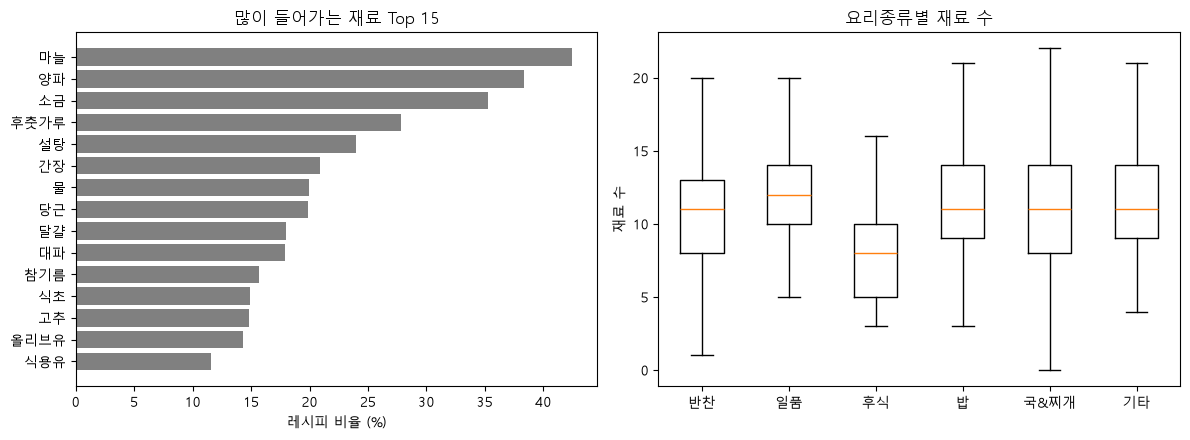

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

top = pd.Series(Counter(x for L in d.ingr for x in L)).nlargest(15)[::-1]
ax[0].barh(top.index, top / len(d) * 100, color='gray')
ax[0].set_xlabel('레시피 비율 (%)')
ax[0].set_title('많이 들어가는 재료 Top 15')

order = table.index
ax[1].boxplot([d[d.RCP_PAT2 == k].n_ingr for k in order], showfliers=False)
ax[1].set_xticks(range(1, len(order) + 1), order)
ax[1].set_ylabel('재료 수')
ax[1].set_title('요리종류별 재료 수')

plt.tight_layout()
plt.savefig('outputs/fig_ingredients.png', dpi=200)
plt.show()

### 냉장고 시뮬레이션
기본 양념 10개 + 달걀, 양파, 두부, 대파가 있을 때 만들 수 있는 레시피가 몇 개인지

In [18]:
basic = {'소금', '설탕', '간장', '식용유', '참기름', '후춧가루', '물', '마늘', '깨', '고춧가루'}
have = basic | {'달걀', '양파', '두부', '대파'}

s = d[d.n_ingr >= 2].copy()
s['missing'] = s.ingr.apply(lambda L: len(set(L) - have))
s['match'] = 1 - s.missing / s.n_ingr

print('레시피 수:', len(s))
print('다 있음:', (s.missing == 0).sum())
print('1개 부족:', (s.missing <= 1).sum())
print('2개 이하 부족:', (s.missing <= 2).sum(), f'({(s.missing <= 2).mean()*100:.1f}%)')
print('50% 이상:', (s.match >= 0.5).sum(), f'({(s.match >= 0.5).mean()*100:.1f}%)')
s.sort_values(['missing', 'match'], ascending=[True, False])[['RCP_NM', 'RCP_PAT2', 'n_ingr', 'missing', 'match']].head(8).round(2)

레시피 수: 1147
다 있음: 0
1개 부족: 1
2개 이하 부족: 18 (1.6%)
50% 이상: 96 (8.4%)


,RCP_NM,RCP_PAT2,n_ingr,missing,match
1098,톳나물 두부무침,반찬,6,1,0.83
548,무대하무침,반찬,9,2,0.78
602,매운락교무침,반찬,7,2,0.71
854,토마토소스 달걀볶음,반찬,7,2,0.71
1022,오이 짱아지 무침,반찬,7,2,0.71
1112,아욱 된장무침,반찬,7,2,0.71
660,감자미역국,국&찌개,6,2,0.67
1013,단호박전,반찬,5,2,0.60


In [19]:
top3 = pd.Series(Counter(x for L in d.ingr for x in L)).nlargest(3) / len(d) * 100
top3.round(0)

마늘    42.0
양파    38.0
소금    35.0
dtype: float64